# Building the table of dredge candidates

A bright spot in a radar image of the Madeira could be a dredge or a bit of riverbank that reflected the signal just as well. I wanted one row for each spot the USGS Local or Global detector flagged on a given date, with a record of whether the analysts had marked a dredge nearby. Looking at the images in notebook 01 gave me a few ideas about what else belonged in that table. Dredges often sat close enough together that it seemed worth counting their neighbors, and I had six other dates to check whether a bright spot stayed put.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from scipy import ndimage
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import cdist, squareform
from skimage.feature import graycomatrix, graycoprops
from skimage.filters import threshold_otsu
from sklearn.cluster import DBSCAN
from sklearn.metrics import roc_auc_score

from helpers import BLUE, ON_DREDGE, ORANGE, OUT, PROC, UTM, chip, db, load_points, pairs, scene, score

local, global_pts, visual = load_points("Local"), load_points("Global"), load_points("Visual")

I treated Local and Global points within 30m of each other on the same date as one candidate. Since the Local detector lined up better with the hand labels in notebook 01, I kept its coordinates and marked the candidate as a hit from both detectors.

In [2]:
both = pairs(local, global_pts)
local_shared, global_shared = (set(x) for x in zip(*both))
cands = gpd.GeoDataFrame(pd.concat([
    local.assign(source=["Both" if i in local_shared else "Local only" for i in range(len(local))]),
    global_pts.drop(index=global_pts.index[list(global_shared)]).assign(source="Global only"),  # global points with no local partner
], ignore_index=True), crs=UTM)

print(f"{len(local)} local + {len(global_pts)} global - {len(both)} shared = {len(cands)} candidates")
cands["source"].value_counts()

254 local + 138 global - 97 shared = 295 candidates


source
Local only     157
Both            97
Global only     41
Name: count, dtype: int64

When two detections land on opposite edges of the same dredge, either one gives the model a reasonable example to learn from. Counting both as separate boats would still be a mistake, which is why I used different distances for labeling candidates and scoring the final detections.

During training, any candidate within 60m of a dredge the analysts marked that day gets a positive label. That covered 251 of the 295 candidates, with only four more between 60 and 500m. For the final score in notebook 03, I merge duplicates and count at most one detection per dredge within 30m, as in notebook 01.

In [3]:
s = score(cands, visual)
print(f"{s['TP']} of {len(visual)} labeled dredges have a candidate within 30m; keeping every candidate scores F1 {s['F1']:.2f}")

# training label: distance from each candidate to the nearest labeled dredge on its date
cands["label_dist_m"] = [visual[visual["date"] == d].distance(p).min() for d, p in zip(cands["date"], cands.geometry)]
cands["dredge"] = (cands["label_dist_m"] <= ON_DREDGE).astype(int)

bins = [0, 30, 60, 100, 500, np.inf]
print(pd.cut(cands["label_dist_m"], bins, labels=["0-30m", "30-60m", "60-100m", "100-500m", "over 500m"]).value_counts().sort_index().to_string())
pd.crosstab(cands["source"], cands["dredge"], margins=True).rename(columns={0: "Not dredge", 1: "On a dredge"})

178 of 204 labeled dredges have a candidate within 30m; keeping every candidate scores F1 0.71
label_dist_m
0-30m        219
30-60m        32
60-100m        1
100-500m       3
over 500m     40


dredge,Not dredge,On a dredge,All
source,,,
Both,4,93,97
Global only,19,22,41
Local only,21,136,157
All,44,251,295


Even if I kept every candidate, only 178 of the 204 usable dredge labels had a match within 30m. That puts 26 dredges out of reach before I even train a model. Keeping all the candidates gave an F1 of 0.71, a small improvement over the Local detector’s 0.69 in notebook 01.

Of the 97 spots that both detectors picked up, only four had no dredge label within 60m. The counts were 19 out of 41 for Global alone and 21 out of 157 for Local alone.

For June 10 I used the radar image I rebuilt in notebook 02_1. I checked for missing pixels around the edges of each 410m window because those values would look like bright land. To keep repeat sightings together for model testing, I grouped candidates into sites wherever their locations connected within 100m across dates.

In [4]:
WIN = 41  # the biggest feature window, in pixels (about 410m)
c0 = WIN // 2  # the window center


def readable(src, p):
    # off the image edge, or into the nodata outside the river corridor
    row, col = src.index(p.x, p.y)
    inside = c0 <= row < src.height - c0 and c0 <= col < src.width - c0
    return inside and not (chip(src, p.x, p.y, WIN) >= src.nodata).any()


for date, idx in cands.groupby("date").groups.items():
    with rasterio.open(scene(date)) as src:
        cands.loc[idx, "readable"] = [readable(src, p) for p in cands.loc[idx].to_crs(src.crs).geometry]

# any two candidates within 100m, on any date, share a site; groups can chain
cands["site"] = DBSCAN(eps=100, min_samples=1).fit_predict(np.c_[cands.geometry.x, cands.geometry.y])
dropped = cands[~cands["readable"].astype(bool)]
cands = cands[cands["readable"].astype(bool)].drop(columns="readable")
print(f"dropped {len(dropped)} candidates ({dropped['dredge'].sum()} dredges) off the image: {dropped['date'].dt.strftime('%b %d').value_counts().to_dict()}")
print(f"{len(cands)} candidates ({cands['dredge'].sum()} dredges) in {cands['site'].nunique()} sites")

dropped 3 candidates (0 dredges) off the image: {'Jul 10': 2, 'Jun 28': 1}
292 candidates (251 dredges) in 109 sites


Three windows extended past the usable image. Dropping them left 292 candidates, including all 251 that fell near labeled dredges and 41 false alarms.

The river is usually darker than the land in radar, though a boat on the water can be as bright as the bank. I used Otsu’s method to pick a VV brightness cutoff for each date and applied it to the 410m window around each candidate. Removing bright patches narrower than about 70m gets rid of most boats and leaves a rough outline of the shore. I measured the distance from each candidate to the nearest pixel left in the land mask.

In [5]:
def water_threshold(src):
    # otsu cutoff on vv (db) from every 10th tile of the scene; zeros are padding, not water
    vals = [src.read(2, window=w, masked=True).compressed() for _, w in list(src.block_windows(2))[::10]]
    vals = np.concatenate([v[v > 0] for v in vals])
    return threshold_otsu(db(vals, 1e-6), nbins=256)


def land_mask(v, thr):
    # bright patches narrower than 7 px (dredges, boats) vanish under opening; banks survive
    return ndimage.binary_opening(v >= thr, structure=np.ones((7, 7)))


def bank_dist(land):
    # meters from the window center to the nearest land pixel; 200m means no bank in view
    return 10 * ndimage.distance_transform_edt(~land)[c0, c0] if land.any() else 10 * c0


vv, vh, thresh = {}, {}, {}
for date, idx in cands.groupby("date").groups.items():
    with rasterio.open(scene(date)) as src:
        thresh[date] = water_threshold(src)
        for i, p in zip(idx, cands.loc[idx].to_crs(src.crs).geometry):
            vh[i], vv[i] = db(chip(src, p.x, p.y, WIN), 1e-6)
cands["dist_bank_m"] = [bank_dist(land_mask(vv[i], thresh[d])) for i, d in zip(cands.index, cands["date"])]
pd.Series({f"{d:%b %d}": round(t, 1) for d, t in thresh.items()}, name="water cutoff (VV dB)").to_frame().T

,Jun 04,Jun 10,Jun 16,Jun 22,Jun 28,Jul 04,Jul 10
water cutoff (VV dB),-14.3,-15.5,-14.9,-15.4,-14.9,-15.3,-15.2


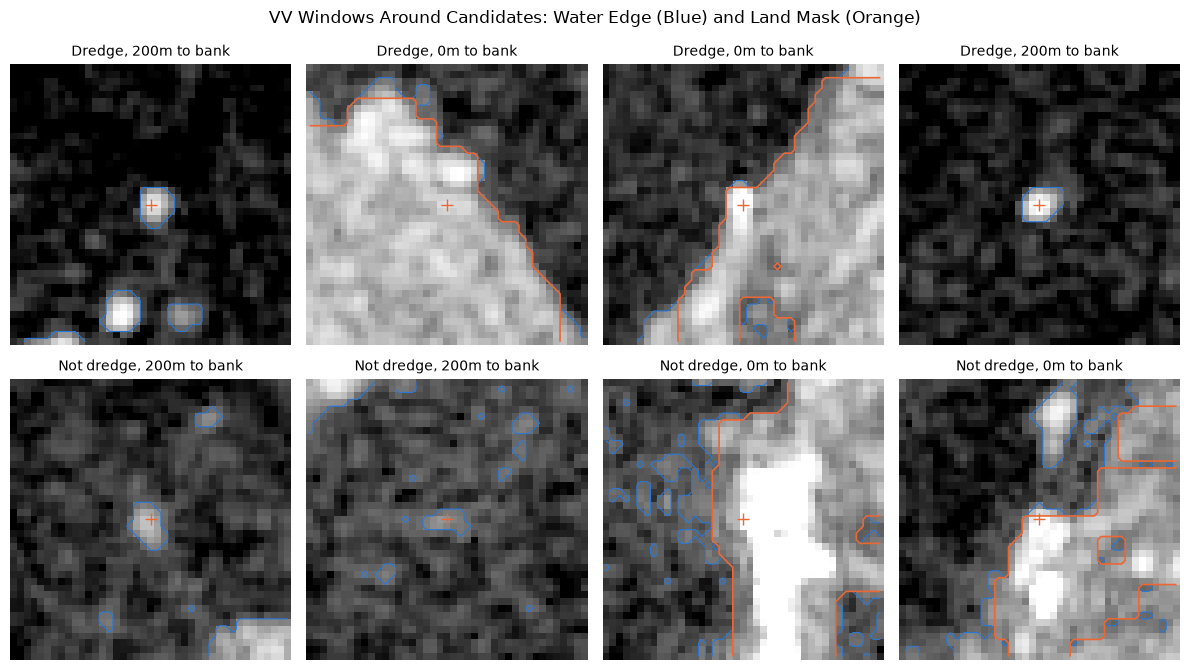

,median,on_land,open_water
dredge,,,
Not dredge,40.0,0.34,0.27
Dredge,200.0,0.22,0.58


In [6]:
# four dredges and four non-dredges, picked at random, with the water edge (blue) and land mask (orange)
sample = pd.concat([cands[cands["dredge"] == k].sample(4, random_state=1) for k in (1, 0)])
fig, axes = plt.subplots(2, 4, figsize=(12, 7))
for ax, (i, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(vv[i], cmap="gray", vmin=-25, vmax=0)
    ax.contour(vv[i] < thresh[r["date"]], levels=[0.5], colors=BLUE, linewidths=0.8)
    ax.contour(land_mask(vv[i], thresh[r["date"]]), levels=[0.5], colors=ORANGE, linewidths=1.2)
    ax.plot(c0, c0, "+", color=ORANGE, markersize=8)
    ax.set_title(f"{'Dredge' if r['dredge'] else 'Not dredge'}, {r['dist_bank_m']:.0f}m to bank", fontsize=10)
    ax.axis("off")
fig.suptitle("VV Windows Around Candidates: Water Edge (Blue) and Land Mask (Orange)")
plt.tight_layout()
plt.show()

# on land = 0m, open water = the 200m cap
cands.groupby("dredge")["dist_bank_m"].agg(median="median", on_land=lambda d: (d == 0).mean(), open_water=lambda d: (d == 10 * c0).mean()).rename(index={0: "Not dredge", 1: "Dredge"}).round(2)

The median false alarm sat 40m from shore, while the median value for dredges was 200m, the distance I recorded when a window contained no shore. The image chips show why I’d still be wary of ruling out spots along the bank. About 22% of dredge candidates fell directly on the land mask, along with 34% of false alarms.

I thought a metal dredge moored against trees might still stand out in one of the two radar bands. In particular, I expected a bigger difference between VV and VH for metal than for vegetation. I measured peak brightness in decibels (dB) over the central 7 × 7 pixels to leave room for the slight offsets I saw in notebook 01.

For each feature, I used ROC AUC to see how often it could put a randomly chosen dredge and false alarm in the right order. I let either direction count, since a low value can be just as useful as a high one. An AUC of 0.5 is chance and 1 is a perfect ranking. I scored all 292 candidates, including the later test sites, and then looked separately at the ones along the bank.

In [7]:
yy, xx = np.ogrid[:WIN, :WIN]
ring = (np.hypot(yy - c0, xx - c0) >= 5) & (np.hypot(yy - c0, xx - c0) <= 10)  # 50-100m out, so the object itself is left out
core = np.s_[c0 - 3:c0 + 4, c0 - 3:c0 + 4]  # the central 7 x 7 px


def peak(v):
    # row and column of the brightest pixel in the core
    r, c = np.unravel_index(v[core].argmax(), (7, 7))
    return r + c0 - 3, c + c0 - 3


def brightness(v_vv, v_vh, thr):
    pk = v_vv[peak(v_vv)]
    water, land = v_vv < thr, land_mask(v_vv, thr)
    return {"vv_peak": pk, "vh_peak": v_vh[core].max(), "vv_minus_vh": pk - v_vh[peak(v_vv)],  # vh at the vv peak pixel
            "contrast_water": pk - np.median(v_vv[water]) if water.any() else np.nan,
            "contrast_land": pk - np.median(v_vv[land]) if land.any() else np.nan,  # nan: no land in view
            "contrast_ring_z": (pk - v_vv[ring].mean()) / v_vv[ring].std()}


def auc(df, col):
    d = df[["dredge", col]].dropna()
    a = roc_auc_score(d["dredge"], d[col])
    return max(a, 1 - a)  # either direction counts


def summary(cols):
    """each feature's auc on its own and its median by class, for all candidates and those at the bank (0m)."""
    out = {}
    for name, df in [("all", cands), ("at bank", cands[cands["dist_bank_m"] == 0])]:
        out[f"AUC, {name} (n = {len(df)})"] = {c: auc(df, c) for c in cols}
        for k, cls in [(1, "dredge"), (0, "not dredge")]:
            out[f"median {cls}, {name}"] = df.loc[df["dredge"] == k, cols].median()
    return pd.DataFrame(out).sort_values(f"AUC, all (n = {len(cands)})", ascending=False).round(2)


cands = cands.join(pd.DataFrame({i: brightness(vv[i], vh[i], thresh[d]) for i, d in zip(cands.index, cands["date"])}).T)
summary(["dist_bank_m", "vv_peak", "vh_peak", "vv_minus_vh", "contrast_water", "contrast_land", "contrast_ring_z"])

,"AUC, all (n = 292)","median dredge, all","median not dredge, all","AUC, at bank (n = 70)","median dredge, at bank","median not dredge, at bank"
vh_peak,0.73,-8.41,-11.72,0.69,-8.25,-9.40
contrast_water,0.71,21.44,15.21,0.57,21.19,22.56
contrast_ring_z,0.68,4.05,2.62,0.51,2.19,2.16
vv_peak,0.68,-0.00,-6.05,0.53,1.78,1.59
dist_bank_m,0.64,200.00,40.00,0.50,0.00,0.00
contrast_land,0.62,8.49,4.32,0.59,8.85,10.79
vv_minus_vh,0.54,10.35,10.63,0.77,12.59,17.24


The median dredge peaked at about 0 dB in VV, roughly 6 dB brighter than the median false alarm. Dredges also stood out more against the ring of pixels around them, with a typical peak 4.1 standard deviations above the ring average versus 2.6 for false alarms. Of the brightness measures, the VH peak did best on its own (AUC 0.73), just ahead of contrast with the water (0.71).

At the bank the difference between VV and VH went the opposite way from what I expected. The median gap was 17.2 dB for false alarms and 12.6 dB for dredges. It separated the two better than contrast with the land did (AUC 0.77 versus 0.59), although there were only 14 false alarms along the bank. I don’t have a good explanation for that reversal.

A patch of riverbank should still be bright a week later, while a dredge may have moved by the next satellite pass. I checked the same spot on the other six dates and recorded how often it was bright. Taking the median VV image across all seven dates also let me redraw the bank without including boats that were there for only a few dates.

In [8]:
srcs = {d: rasterio.open(scene(d)) for d in thresh}  # every scene is on a wgs84 grid
for i, p in zip(cands.index, cands.to_crs("EPSG:4326").geometry):
    wins = {d: db(chip(src, p.x, p.y, WIN, band=2), 1e-6) for d, src in srcs.items()}
    cands.loc[i, "other_dates_bright"] = np.mean([w[c0 - 2:c0 + 3, c0 - 2:c0 + 3].max() >= thresh[d] for d, w in wins.items() if d != cands.at[i, "date"]])
    # the median across dates keeps permanent land and drops objects that come and go
    cands.loc[i, "dist_bank_7d_m"] = bank_dist(land_mask(np.median(list(wins.values()), axis=0), np.median(list(thresh.values()))))
for src in srcs.values():
    src.close()
summary(["other_dates_bright", "dist_bank_7d_m"])

,"AUC, all (n = 292)","median dredge, all","median not dredge, all","AUC, at bank (n = 70)","median dredge, at bank","median not dredge, at bank"
other_dates_bright,0.75,0.17,1.0,0.71,0.83,1.0
dist_bank_7d_m,0.68,200.00,40.0,0.60,0.00,0.0


The same spot stayed bright on all six other dates for 61% of the false alarms, compared with 13% of the dredges. That fits what I’d expect from a rock or a bit of bright bank that keeps triggering the detector. For dredges away from the bank, the median number of other dates with a bright return was zero. This measure of persistence had an AUC of 0.75 overall and 0.71 at the bank.

Using all seven dates to locate the shoreline improved the AUC for bank distance from 0.50 to 0.60 at the bank. Across all candidates the change was smaller, from 0.64 to 0.68.

At 10m per pixel, a dredge 10 to 30m long spans only a few pixels. I wanted to see whether its outline still looked smaller or rounder than a patch of bank. Starting from the brightest pixel near the center, I traced the connected pixels within 6 dB of that peak and measured the area and elongation of the resulting patch.

A lone dredge with calm water on all sides should also have a smoother background than one moored against the bank. To measure that, I took the standard deviation of VV across the window and in a ring 50 to 100m from the candidate.

In [9]:
def shape_texture(v):
    labels, _ = ndimage.label(v >= v[peak(v)] - 6)  # the object: pixels within 6 db of the peak that connect to it
    blob = labels == labels[peak(v)]
    # the blob's spread along its long and short axes; 1/12 is one pixel's own spread
    ev = np.linalg.eigvalsh(np.cov(np.nonzero(blob))) if blob.sum() > 2 else np.zeros(2)
    return {"blob_area_px": blob.sum(), "elongation": np.sqrt((ev[-1] + 1 / 12) / (ev[0] + 1 / 12)), "ring_std": v[ring].std(), "window_std": v.std()}


cands = cands.join(pd.DataFrame({i: shape_texture(vv[i]) for i in cands.index}).T.astype(float))
summary(["blob_area_px", "elongation", "ring_std", "window_std"])

,"AUC, all (n = 292)","median dredge, all","median not dredge, all","AUC, at bank (n = 70)","median dredge, at bank","median not dredge, at bank"
window_std,0.63,5.35,6.44,0.76,6.88,7.56
blob_area_px,0.62,14.00,18.00,0.50,33.50,31.50
ring_std,0.56,5.04,5.65,0.76,6.35,7.47
elongation,0.53,1.45,1.44,0.52,1.69,1.79


I thought the dredges would look rounder than the bits of bank, but they had almost the same elongation as the false alarms. Area gave me a little more to work with, at a median of 14 pixels for dredges and 18 for false alarms. False alarms generally had a noisier background, with a median spread of 6.4 dB across the window compared with 5.4 dB for dredges. The spread in the ring and across the window both did best at the bank (AUC 0.76), where I had only 14 false alarms to go on.

Two windows can have the same spread in brightness even if one has smooth patches and the other has light and dark pixels mixed together. A matrix called a GLCM counts how often each pair of gray levels shows up in neighboring pixels. I grouped VV values from −25 to 5 dB into 16 levels in the central 21 × 21 pixels, then averaged the texture measures across four directions using neighbors one and two pixels apart.

In [10]:
LEVELS, LO, HI = 16, -25, 5  # a fixed db range, so every candidate uses the same bins


def glcm_features(v):
    q = np.clip((v[c0 - 10:c0 + 11, c0 - 10:c0 + 11] - LO) / (HI - LO) * LEVELS, 0, LEVELS - 1).astype(np.uint8)
    # neighbors 1 and 2 pixels away in four directions, counted both ways and normalized
    g = graycomatrix(q, distances=[1, 2], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4], levels=LEVELS, symmetric=True, normed=True)
    out = {f"glcm_{p}": graycoprops(g, p).mean() for p in ["contrast", "homogeneity", "energy", "correlation"]}
    out["glcm_entropy"] = np.mean([-(m[m > 0] * np.log2(m[m > 0])).sum() for m in g.reshape(LEVELS * LEVELS, -1).T])
    return out


glcm = pd.DataFrame({i: glcm_features(vv[i]) for i in cands.index}).T.astype(float)
cands = cands.join(glcm)
summary(list(glcm.columns)).assign(spearman_with_ring_std=cands[glcm.columns].corrwith(cands["ring_std"], method="spearman").round(2))

,"AUC, all (n = 292)","median dredge, all","median not dredge, all","AUC, at bank (n = 70)","median dredge, at bank","median not dredge, at bank",spearman_with_ring_std
glcm_contrast,0.65,3.39,2.93,0.56,3.56,3.72,0.58
glcm_energy,0.61,0.22,0.20,0.57,0.15,0.16,-0.52
glcm_entropy,0.58,5.21,5.41,0.52,6.05,5.97,0.67
glcm_correlation,0.52,0.80,0.84,0.72,0.86,0.88,0.85
glcm_homogeneity,0.51,0.55,0.56,0.59,0.52,0.54,-0.50


Of the five GLCM measures, contrast did best across all candidates (AUC 0.65). GLCM correlation was the only one above 0.70 at the bank. Across the full set, GLCM correlation tracked the spread of VV in the ring (Spearman 0.85), and entropy tended to rise closer to shore (−0.72 with bank distance). I kept them to see whether they’d add anything once the model had access to the simpler features too.

Several dredges in the image chips were moored together, so I counted the other candidates within 200m of each spot on the same date. I also kept two yes/no columns for which detector found each spot, one for hits from both detectors and one for Global alone.

In [11]:
xy = np.c_[cands.geometry.x, cands.geometry.y]
same_day = cands["date"].values[:, None] == cands["date"].values[None, :]
cands["neighbors_200m"] = ((cdist(xy, xy) <= 200) & same_day).sum(axis=1) - 1  # minus one so a candidate doesn't count itself
cands["found_by_both"] = (cands["source"] == "Both").astype(int)
cands["global_only"] = (cands["source"] == "Global only").astype(int)
display(summary(["neighbors_200m", "found_by_both", "global_only"]))

cols = list(cands.loc[:, "dist_bank_m":].columns)  # all 21 features
cands.drop(columns="label_dist_m").to_file(PROC / "candidates.gpkg", driver="GPKG")
print(f"saved {len(cands)} candidates x {len(cols)} features to {PROC / 'candidates.gpkg'}")

,"AUC, all (n = 292)","median dredge, all","median not dredge, all","AUC, at bank (n = 70)","median dredge, at bank","median not dredge, at bank"
neighbors_200m,0.77,2.0,0.0,0.90,6.0,0.0
global_only,0.68,0.0,0.0,0.75,0.0,1.0
found_by_both,0.64,0.0,0.0,0.56,0.0,0.0


saved 292 candidates x 21 features to ../data/processed/candidates.gpkg


About 71% of the dredge candidates had a neighbor within 200m, compared with 29% of false alarms. Dredges working in groups probably explain some of that difference, though two detections on the same boat also count as neighbors here. The count had an AUC of 0.77, the highest I got from any one feature across the full set.

I’d be more suspicious of a spot that only Global picked up. Among the remaining candidates, 45% of the ones Global found alone were false alarms. When both detectors found a spot, that figure was 4%. Those source columns depend on having results from both USGS detectors. The full table in `data/processed/candidates.gpkg` has 292 rows and 21 features.

In the heat map below I grouped features that tend to change together, even when they move in opposite directions. The dredge label is in the bottom row so I can see how closely each feature tracks it.

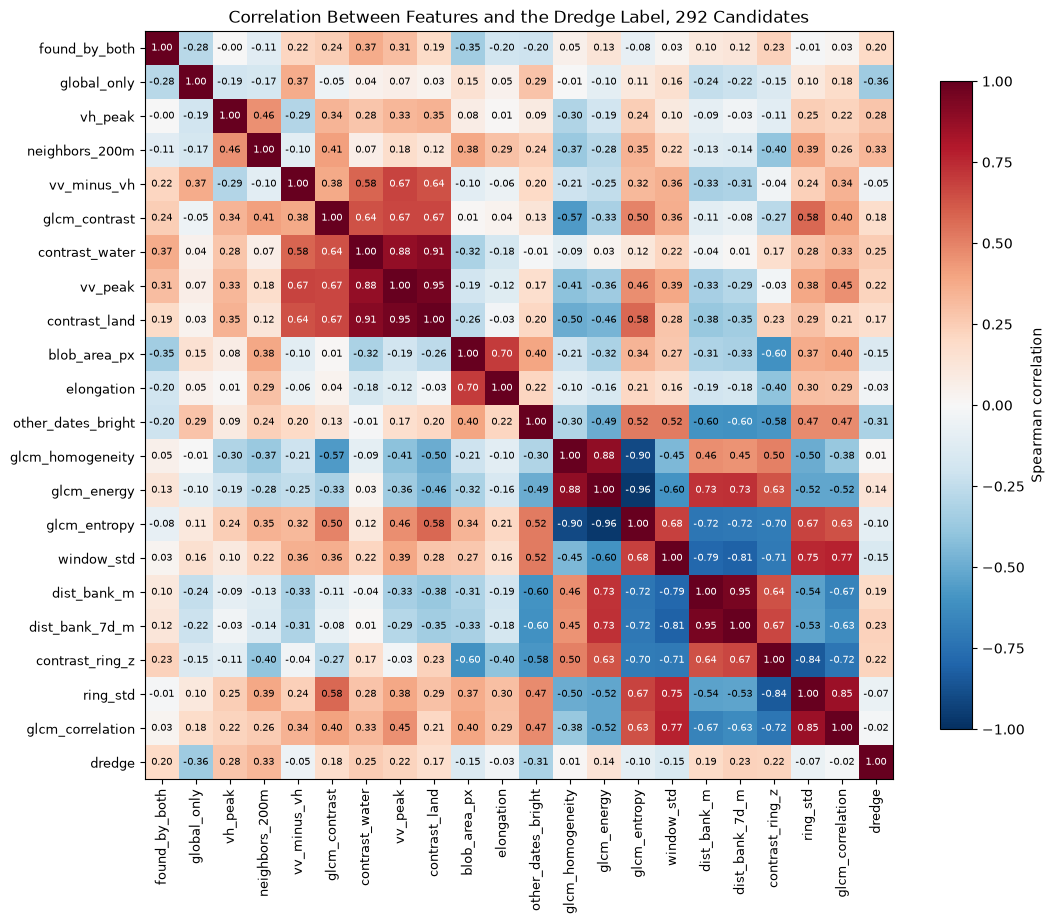

Spearman
glcm_energy      glcm_entropy         -0.96
vv_peak          contrast_land         0.95
dist_bank_m      dist_bank_7d_m        0.95
contrast_water   contrast_land         0.91
glcm_homogeneity glcm_entropy         -0.90
                 glcm_energy           0.88
vv_peak          contrast_water        0.88
ring_std         glcm_correlation      0.85
contrast_ring_z  ring_std             -0.84
dist_bank_7d_m   window_std           -0.81
dist_bank_m      window_std           -0.79
window_std       glcm_correlation      0.77
ring_std         window_std            0.75
dist_bank_7d_m   glcm_energy           0.73
dist_bank_m      glcm_energy           0.73
                 glcm_entropy         -0.72
contrast_ring_z  glcm_correlation     -0.72
dist_bank_7d_m   glcm_entropy         -0.72
contrast_ring_z  window_std           -0.71

,correlation with dredge
global_only,-0.36
neighbors_200m,0.33
other_dates_bright,-0.31
vh_peak,0.28
contrast_water,0.25
dist_bank_7d_m,0.23
contrast_ring_z,0.22
vv_peak,0.22
found_by_both,0.20
dist_bank_m,0.19


In [12]:
# spearman ranks, so skewed features like blob area don't distort the correlation
corr = cands[cols + ["dredge"]].astype(float).corr(method="spearman")
# order features by similarity (1 - |r|) so overlapping groups sit together; the label goes last
order = [cols[k] for k in leaves_list(linkage(squareform(1 - corr.loc[cols, cols].abs().values, checks=False), "average"))] + ["dredge"]
corr = corr.loc[order, order]

fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
for r in range(len(order)):
    for c in range(len(order)):
        ax.text(c, r, f"{corr.iat[r, c]:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(corr.iat[r, c]) > 0.6 else "black")
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=9)
ax.set_yticks(range(len(order)), order, fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
ax.set_title(f"Correlation Between Features and the Dredge Label, {len(cands)} Candidates")
plt.tight_layout()
plt.savefig(OUT / "02_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# feature pairs that mostly repeat each other
pairs_hi = corr.loc[cols, cols].where(np.triu(np.ones((len(cols), len(cols)), bool), 1)).stack()
display(pairs_hi[pairs_hi.abs() >= 0.7].sort_values(key=abs, ascending=False).round(2).to_frame("Spearman"))
corr["dredge"].drop("dredge").sort_values(key=abs, ascending=False).round(2).to_frame("correlation with dredge")

What surprised me in the heat map was how many measurements grouped together around distance to the bank. Where a window includes shore, the mix of bright land and dark water makes the pixels more variable. Distance to the bank groups together with the spread in VV, the contrast around the candidate, and four of the five GLCM measures. Even persistence falls in that group, which makes sense if the same stretch of bank keeps lighting up. With more examples, I’d like to try training a separate model for dredges along the bank.

Some pairs of features are almost interchangeable. The two estimates of bank distance have a correlation of 0.95, and GLCM energy and entropy go in opposite directions almost perfectly (−0.96). Peak brightness and contrast with land or water form a group of their own, with correlations from 0.88 to 0.95. My rough count from the plot is closer to eight or nine distinct patterns among the 21 columns.

The correlations with the dredge label itself are much smaller. The biggest values in the bottom row belonged to detections from Global alone (−0.36), the number of neighbors (0.33) and persistence (−0.31). I kept the full set for notebook 03, where I can leave out a group of features and see whether the predictions actually change. The figure for the report is in `outputs/02_correlation_matrix.png`.